# Análise de Vendas

## Introdução

Este projeto tem como objetivo analisar uma base de dados de vendas para entender melhor o comportamento das vendas, observando as diferenças entre regiões, categorias de produtos, canais de venda e tipos de clientes. Para isso, foram realizadas análises e gráficos para explorar os dados e identificar possíveis padrões.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**1.Explorando a qualidade dos dados**

In [4]:
df = pd.read_csv('sales_data.csv')

In [7]:
df.head()

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie


In [12]:
df.dtypes

Product_ID                int64
Sale_Date                   str
Sales_Rep                   str
Region                      str
Sales_Amount            float64
Quantity_Sold             int64
Product_Category            str
Unit_Cost               float64
Unit_Price              float64
Customer_Type               str
Discount                float64
Payment_Method              str
Sales_Channel               str
Region_and_Sales_Rep        str
dtype: object

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Product_ID            1000 non-null   int64  
 1   Sale_Date             1000 non-null   str    
 2   Sales_Rep             1000 non-null   str    
 3   Region                1000 non-null   str    
 4   Sales_Amount          1000 non-null   float64
 5   Quantity_Sold         1000 non-null   int64  
 6   Product_Category      1000 non-null   str    
 7   Unit_Cost             1000 non-null   float64
 8   Unit_Price            1000 non-null   float64
 9   Customer_Type         1000 non-null   str    
 10  Discount              1000 non-null   float64
 11  Payment_Method        1000 non-null   str    
 12  Sales_Channel         1000 non-null   str    
 13  Region_and_Sales_Rep  1000 non-null   str    
dtypes: float64(4), int64(2), str(8)
memory usage: 109.5 KB


In [52]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'])

In [107]:
df.shape

(1000, 14)

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Product_ID,1000.0,1050.12800,29.573505,1001.00,1024.0000,1051.000,1075.000,1100.00
Sales_Amount,1000.0,5019.26523,2846.790126,100.12,2550.2975,5019.300,7507.445,9989.04
Quantity_Sold,1000.0,25.35500,14.159006,1.00,13.0000,25.000,38.000,49.00
Unit_Cost,1000.0,2475.30455,1417.872546,60.28,1238.3800,2467.235,3702.865,4995.30
Unit_Price,1000.0,2728.44012,1419.399839,167.12,1509.0850,2696.400,3957.970,5442.15
Discount,1000.0,0.15239,0.087200,0.00,0.0800,0.150,0.230,0.30


In [15]:
df.isnull().sum()

Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

In [25]:
for coluna in df.columns:
    print(df[coluna].value_counts())

Product_ID
1090    20
1092    19
1062    19
1033    18
1099    18
        ..
1068     5
1083     4
1041     4
1011     4
1031     3
Name: count, Length: 100, dtype: int64
Sale_Date
2023-11-14    8
2023-10-20    8
2023-08-14    7
2023-10-16    7
2023-11-24    7
             ..
2023-11-13    1
2023-12-14    1
2023-08-26    1
2023-08-09    1
2023-07-26    1
Name: count, Length: 340, dtype: int64
Sales_Rep
David      222
Eve        209
Bob        208
Alice      192
Charlie    169
Name: count, dtype: int64
Region
North    267
East     263
West     244
South    226
Name: count, dtype: int64
Sales_Amount
6116.75    2
7946.69    2
5053.97    1
4384.02    1
4631.23    1
          ..
4733.88    1
4716.36    1
7629.70    1
1629.47    1
4923.93    1
Name: count, Length: 998, dtype: int64
Quantity_Sold
47    32
17    28
45    28
32    26
35    26
42    26
43    25
23    25
16    25
12    24
4     24
14    23
40    22
19    22
11    22
28    22
26    22
20    22
46    21
31    21
22    21
2     21
2

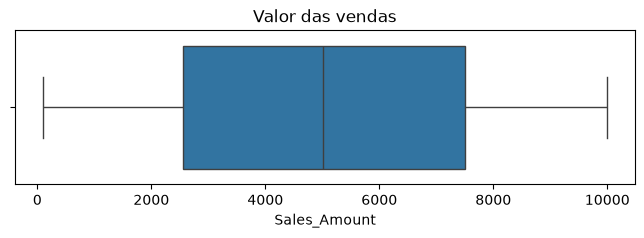

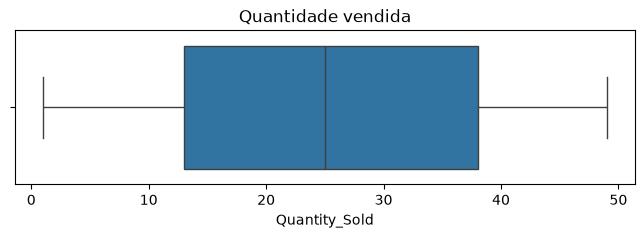

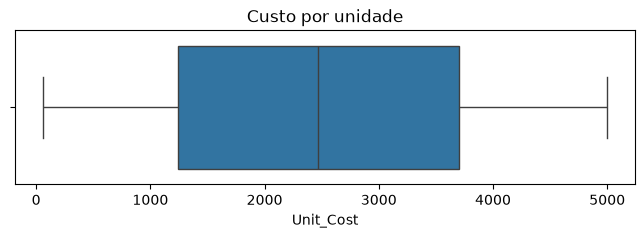

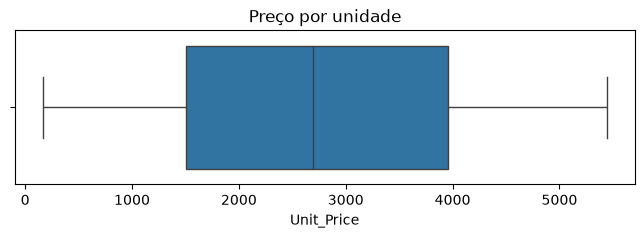

In [36]:
plt.figure(figsize=(8, 2))
sns.boxplot(x=df['Sales_Amount'])
plt.title('Valor das vendas')
plt.show()

plt.figure(figsize=(8, 2))
sns.boxplot(x=df['Quantity_Sold'])
plt.title('Quantidade vendida')
plt.show()

plt.figure(figsize=(8, 2))
sns.boxplot(x=df['Unit_Cost'])
plt.title('Custo por unidade')
plt.show()

plt.figure(figsize=(8, 2))
sns.boxplot(x=df['Unit_Price'])
plt.title('Preço por unidade')
plt.show()

**Não foram observados outliers visualmente nos boxplots.**

**2.Análise de Vendas**

In [38]:
df.groupby('Region')['Sales_Amount'].sum().sort_values(ascending=False)

Region
North    1369612.51
East     1259792.93
West     1235608.93
South    1154250.86
Name: Sales_Amount, dtype: float64

In [44]:
df['Region'].value_counts()

Region
North    267
East     263
West     244
South    226
Name: count, dtype: int64

In [39]:
df.groupby('Product_Category')['Sales_Amount'].sum().sort_values(ascending=False)

Product_Category
Clothing       1313474.36
Furniture      1260517.69
Electronics    1243499.64
Food           1201773.54
Name: Sales_Amount, dtype: float64

In [45]:
df['Product_Category'].value_counts()

Product_Category
Clothing       268
Furniture      260
Electronics    246
Food           226
Name: count, dtype: int64

In [40]:
df.groupby('Sales_Channel')['Sales_Amount'].sum().sort_values(ascending=False)

Sales_Channel
Retail    2560431.30
Online    2458833.93
Name: Sales_Amount, dtype: float64

In [43]:
df['Sales_Channel'].value_counts()

Sales_Channel
Retail    512
Online    488
Name: count, dtype: int64

In [46]:
df.groupby('Sales_Rep')['Sales_Amount'].sum().sort_values(ascending=False)

Sales_Rep
David      1141737.36
Bob        1080990.63
Eve         970183.99
Alice       965541.77
Charlie     860811.48
Name: Sales_Amount, dtype: float64

In [47]:
df['Sales_Rep'].value_counts()

Sales_Rep
David      222
Eve        209
Bob        208
Alice      192
Charlie    169
Name: count, dtype: int64

In [49]:
df.groupby('Customer_Type')['Sales_Amount'].sum().sort_values(ascending=False)

Customer_Type
Returning    2513006.93
New          2506258.30
Name: Sales_Amount, dtype: float64

In [50]:
df['Customer_Type'].value_counts()

Customer_Type
New          504
Returning    496
Name: count, dtype: int64

In [53]:
df.groupby(df['Sale_Date'].dt.month)['Sales_Amount'].sum()

Sale_Date
1     495420.37
2     368919.36
3     402638.77
4     438992.61
5     389078.76
6     418458.34
7     374242.88
8     443171.28
9     367837.60
10    460378.78
11    467482.90
12    392643.58
Name: Sales_Amount, dtype: float64

<Axes: xlabel='Sale_Date'>

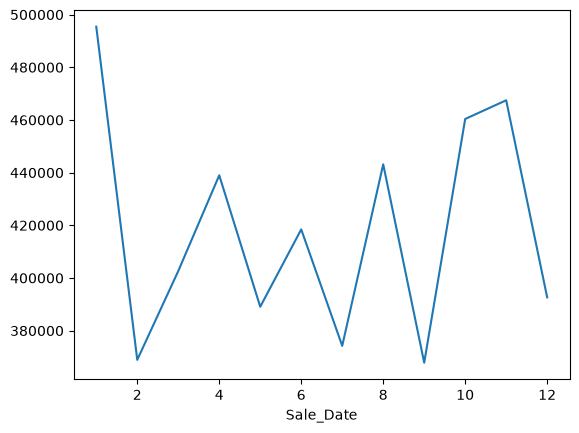

In [58]:
vendas_mes = df.groupby(df['Sale_Date'].dt.month)['Sales_Amount'].sum()

vendas_mes.plot()

**O mês de Janeiro teve o maior valor de venda**

**3.Explorando relação entre as variáveis**

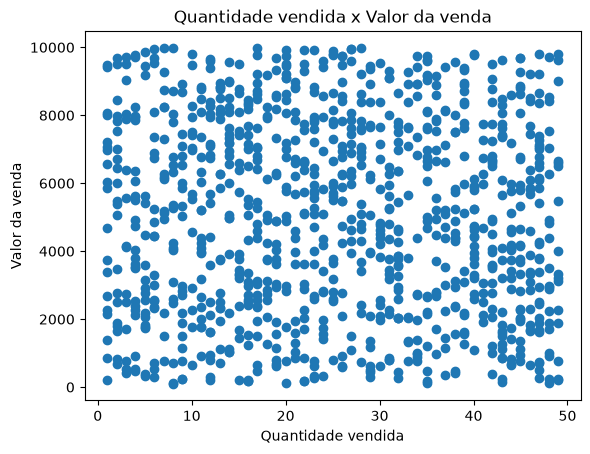

In [59]:
plt.scatter(df['Quantity_Sold'], df['Sales_Amount'])
plt.xlabel("Quantidade vendida")
plt.ylabel("Valor da venda")
plt.title("Quantidade vendida x Valor da venda")
plt.show()

In [60]:
df['Quantity_Sold'].corr(df['Sales_Amount'])

np.float64(-0.0415987049808268)

**Não há associação linear relevante entre quantidade vendida e valor da venda**

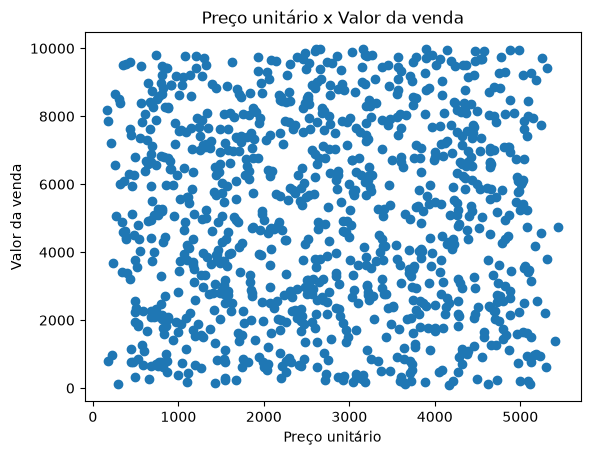

In [62]:
plt.scatter(df['Unit_Price'], df['Sales_Amount'])
plt.xlabel("Preço Unitário")
plt.ylabel("Valor da venda")
plt.title("Preço unitário x Valor da venda")
plt.show()

In [63]:
df['Unit_Price'].corr(df['Sales_Amount'])

np.float64(0.011812023736311163)

**Não há associação linear relevante entre preço unitário e valor da venda**

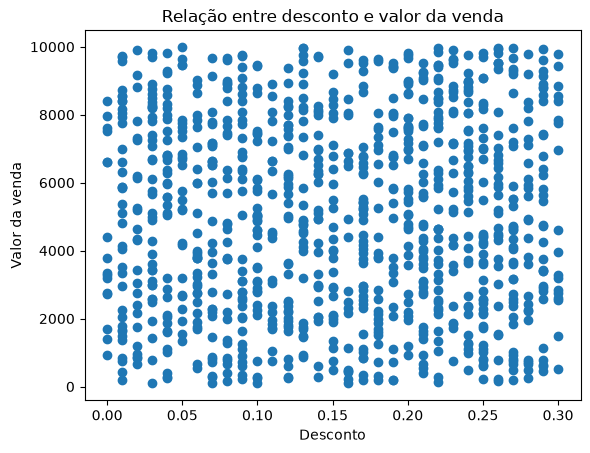

In [64]:
plt.scatter(df['Discount'], df['Sales_Amount'])
plt.xlabel("Desconto")
plt.ylabel("Valor da venda")
plt.title("Relação entre desconto e valor da venda")
plt.show()

In [65]:
df['Discount'].corr(df["Sales_Amount"])

np.float64(0.02315270334119758)

**Não há associação linear relevante entre desconto e valor da venda**

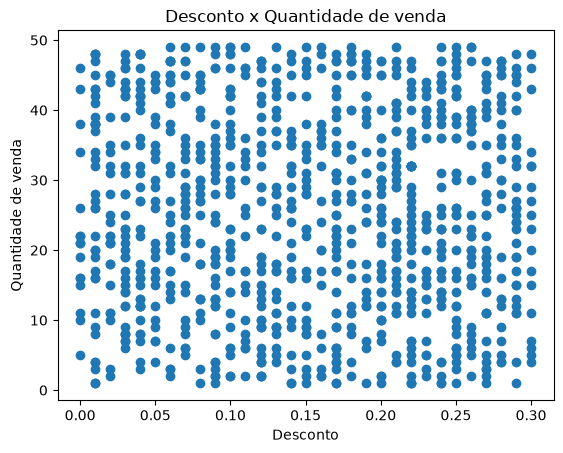

In [70]:
plt.scatter(df['Discount'], df['Quantity_Sold'])
plt.xlabel("Desconto")
plt.ylabel("Quantidade de venda")
plt.title("Desconto x Quantidade de venda")
plt.show()

In [71]:
df['Discount'].corr(df["Quantity_Sold"])

np.float64(-0.007806260114458755)

**Não há associação linear relevante entre desconto e quantidade de venda**

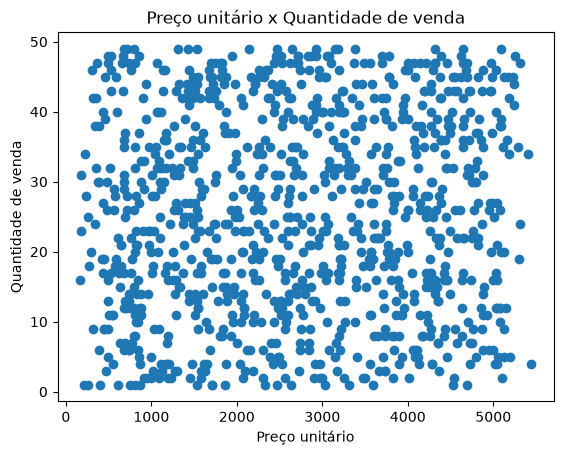

In [72]:
plt.scatter(df['Unit_Price'], df['Quantity_Sold'])
plt.xlabel("Preço Unitário")
plt.ylabel("Quantidade de venda")
plt.title("Preço unitário x Quantidade de venda")
plt.show()

In [74]:
df['Unit_Price'].corr(df["Quantity_Sold"])

np.float64(0.05729592936758643)

**Não há associação linear relevante entre preço unitário e quantidade de venda**

In [76]:
df.groupby('Product_Category')['Quantity_Sold'].mean().sort_values(ascending=False)

Product_Category
Furniture      25.880769
Clothing       25.828358
Food           24.814159
Electronics    24.780488
Name: Quantity_Sold, dtype: float64

**A categoria Furniture (móveis) apresentou a maior quantidade média vendida por transação (25,88 unidades), enquanto Electronics apresentou a menor (24,78 unidades). Porém, as médias são bastante próximas, indicando pouca diferença entre as categorias quanto à quantidade média vendida por transação.**

In [78]:
df.groupby('Product_Category')['Quantity_Sold'].sum().sort_values(ascending=False)

Product_Category
Clothing       6922
Furniture      6729
Electronics    6096
Food           5608
Name: Quantity_Sold, dtype: int64

In [82]:
vendas_mes_categoria = df.groupby([df['Sale_Date'].dt.month, 'Product_Category'])['Sales_Amount'].sum().unstack()
vendas_mes_categoria

Product_Category,Clothing,Electronics,Food,Furniture
Sale_Date,,,,
1,132877.78,105483.44,94765.52,162293.63
2,90815.67,89530.85,91206.13,97366.71
3,128934.01,97875.50,87969.27,87859.99
4,99974.35,127514.53,126410.50,85093.23
5,97836.73,72189.35,97178.92,121873.76
6,89701.64,123107.56,58406.76,147242.38
7,91222.38,112643.73,79491.25,90885.52
8,148120.35,92009.25,120341.76,82699.92
9,85187.83,104785.10,91081.50,86783.17


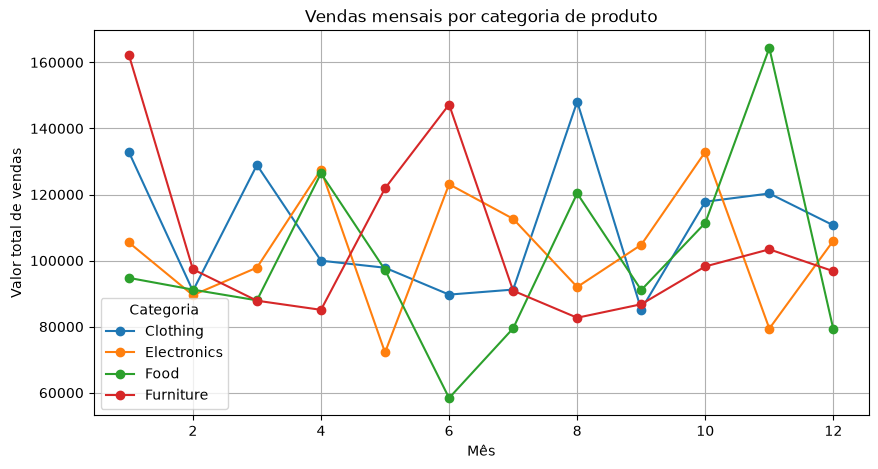

In [89]:
vendas_mes_categoria.plot(figsize=(10,5), marker='o')
plt.xlabel("Mês")
plt.ylabel("Valor total de vendas")
plt.title("Vendas mensais por categoria de produto")
plt.legend(title='Categoria')
plt.grid(True)
plt.show()

In [91]:
df.groupby('Product_Category')['Discount'].mean().sort_values(ascending=False)

Product_Category
Clothing       0.160224
Furniture      0.158115
Food           0.153805
Electronics    0.136504
Name: Discount, dtype: float64

In [102]:
sorted(df['Sale_Date'].dt.year.unique())

[np.int32(2023), np.int32(2024)]

In [103]:
df.groupby(df['Sale_Date'].dt.year)['Sales_Amount'].sum()

Sale_Date
2023    4999937.22
2024      19328.01
Name: Sales_Amount, dtype: float64

In [104]:
df['Sale_Date'].dt.year.value_counts().sort_index()

Sale_Date
2023    997
2024      3
Name: count, dtype: int64

In [105]:
df[df['Sale_Date'].dt.year == 2024]['Sale_Date']

317   2024-01-01
627   2024-01-01
873   2024-01-01
Name: Sale_Date, dtype: datetime64[us]

In [106]:
df[df['Sale_Date'].dt.year == 2024]

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
317,1018,2024-01-01,Alice,West,8579.72,24,Electronics,1362.78,1729.81,New,0.29,Bank Transfer,Online,West-Alice
627,1078,2024-01-01,David,East,8377.57,42,Food,63.41,314.93,Returning,0.03,Cash,Retail,East-David
873,1098,2024-01-01,Bob,South,2370.72,11,Clothing,213.41,503.36,Returning,0.27,Bank Transfer,Online,South-Bob


In [109]:
df.to_csv('vendas_tratadas.csv', index=False, encoding='utf-8-sig')

<font size="5">**Conclusão**</font>

Este projeto de análise exploratória de dados teve como objetivo compreender o comportamento das vendas e identificar padrões e diferenças entre regiões, categorias de produtos, canais de venda, representantes comerciais, tipos de clientes e períodos.

Inicialmente, foi verificada a qualidade dos dados por meio da busca por valores ausentes e registros duplicados, que não foram encontrados. Também foi realizada uma análise de possíveis outliers nas variáveis numéricas selecionadas, sem identificação de valores fora dos limites estabelecidos pelo método do intervalo interquartil (IQR).

Em relação ao desempenho das vendas, observou-se que, entre as **regiões**, *North* apresentou o maior valor total de vendas e o maior número de registros, enquanto *South* apresentou os menores resultados em ambos os indicadores.

Entre as **categorias de produtos**, *Clothing (roupas)* apresentou o maior valor total de vendas e o maior número de registros, enquanto *Food (comida)* apresentou os menores resultados nesses indicadores. Quanto ao **canal de vendas**, *Retail (varejo)* registrou o maior valor total de vendas e o maior número de registros.

No que diz respeito aos **representantes de venda**, *David* apresentou o maior valor total de vendas e o maior número de registros, enquanto *Charlie* apresentou os menores resultados em ambos os indicadores. Na análise por **tipo de cliente**, os clientes *Returning (recorrentes)* apresentaram o maior valor total de vendas, enquanto os clientes *New (novos)* tiveram o maior número de registros.

A **análise mensal** revelou que janeiro apresentou o maior valor total de vendas, enquanto setembro apresentou o menor.

Pudemos observar que, nesta base, não há associação linear relevante entre as variáveis quantidade vendida, preço unitário e desconto e a variável valor da venda. Igualmente, não há associação linear relevante entre as variáveis desconto e preço unitário e a variável quantidade vendida.

A categoria *Furniture (móveis)* apresentou a maior quantidade média vendida por transação (25,88 unidades), enquanto *Electronics* apresentou a menor (24,78 unidades). Porém, as médias são bastante próximas, indicando pouca diferença entre as categorias quanto à quantidade média vendida por transação.

A análise dos **descontos** por **categoria** mostrou que *Clothing* apresentou a maior média de descontos (aproximadamente 16,02%), enquanto *Electronics* apresentou a menor (aproximadamente 13,65%). Essa diferença não permite concluir que os descontos causaram alterações no valor das vendas.

Por fim, apesar de existirem registros de dois anos diferentes na base (2023 e 2024), a grande maioria corresponde a 2023, com apenas três registros de 2024, o que não nos permite fazer uma comparação de vendas por ano. 

Conclui-se que a análise exploratória permitiu identificar diferenças no desempenho das vendas entre regiões, categorias de produtos, canais de venda, representantes comerciais e tipos de clientes, além de variações mensais e diferenças nas quantidades médias vendidas e nos descontos por categoria. Os resultados contribuem para a compreensão do conjunto de dados, mas devem ser interpretados considerando as limitações da base analisada.